# Interpretabilidad de los Modelos Finales

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

pd.set_option("display.max_colwidth", None)

from Interpretabilidad import (
    SEED, NOMBRE_SEXO,
    cargar_modelos, verificar_modelos, preparar_datos, extraer_componentes, nombres_legibles, transformar, valores_originales,
    tabla_coeficientes, graficar_coeficientes,
    importancia_catboost, graficar_importancia_catboost,
    shap_catboost, shap_lineal, verificar_aditividad, salida_logodds_catboost, importancia_shap,
    graficar_shap_barras, graficar_shap_beeswarm, graficar_dependencias, graficar_waterfall,
    elegir_casos_clasificacion, elegir_casos_regresion,
    crear_explicador_lime, explicar_lime, graficar_lime, comparar_lime_shap,
    importancia_permutacion, graficar_permutacion,
    tabla_importancias, guardar_resultados,
)

/opt/conda/envs/screen-time-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Carga de los Modelos

In [2]:
modelos = cargar_modelos()
clasificador, metadatos_clf = modelos["clasificador"], modelos["metadatos_clf"]
regresor, metadatos_reg = modelos["regresor"], modelos["metadatos_reg"]
UMBRAL = metadatos_clf["umbral"]

verificar_modelos(modelos)

,Modelo (metadatos),Estimador final,Variante,Umbral,Hiperparámetros,Correcto
Problema,,,,,,
Clasificación (depressed),CatBoost,CatBoostClassifier,estrategia nativo,0.15342,"{'depth': 4, 'iterations': 232, 'l2_leaf_reg': 1.5720251525742128, 'learning_rate': 0.02538617845650057}",True
Regresión (bdi_total),ElasticNet,ElasticNet,target nativo,NaN,"{'alpha': 0.01444525102276306, 'l1_ratio': 0.3329833121584336}",True


### Datos: Split y Test

El test se reconstruye desde `split_indices.csv`, el mismo de todo el modelado, y todas las explicaciones se calculan sobre él. El train solo se usa como referencia: datos de fondo de SHAP en el ElasticNet y distribución de referencia de LIME.

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

datos = preparar_datos(df)
X_train, X_test = datos["X_train"], datos["X_test"]
y_dep_test, y_bdi_test, subject_id_test = datos["y_dep_test"], datos["y_bdi_test"], datos["subject_id_test"]

pd.DataFrame({
    "Filas": [len(X_train), len(X_test)],
    "Deprimidos": [None, int(y_dep_test.sum())],
    "BDI medio": [None, round(y_bdi_test.mean(), 2)],
}, index=pd.Index(["Train (referencia)", "Test"], name="Conjunto"))

,Filas,Deprimidos,BDI medio
Conjunto,,,
Train (referencia),3848,NaN,NaN
Test,962,157.0,7.15


### Componentes de los Pipelines

De cada pipeline se extraen el preprocesador ajustado (`StandardScaler` + `OneHotEncoder(drop="first")`), el estimador final y los nombres de las variables transformadas (`get_feature_names_out`). Los dos modelos comparten el mismo preprocesamiento, así que ven las mismas 6 columnas en el mismo orden. Para las gráficas se usan los nombres legibles y los valores originales de cada variable (sin estandarizar); `sex` se representa como 0 = chico y 1 = chica.

In [4]:
prep_clf, catboost, nombres_clf = extraer_componentes(clasificador)
prep_reg, elasticnet, nombres_reg = extraer_componentes(regresor)
assert nombres_clf == nombres_reg, "Los dos pipelines deberían producir las mismas columnas"

nombres = nombres_legibles(nombres_clf)

# Test preprocesado con el preprocesador de cada modelo y valores originales para las gráficas
X_test_clf = transformar(prep_clf, X_test)
X_test_reg = transformar(prep_reg, X_test)
X_train_reg = transformar(prep_reg, X_train)
originales_test = valores_originales(X_test, nombres_clf)

pd.DataFrame({"Variable transformada": nombres_clf, "Nombre legible": nombres})

,Variable transformada,Nombre legible
0,numericas__sleep_quality_index,Índice de calidad del sueño
1,numericas__avg_sleep_hours,Horas de sueño promedio
2,numericas__midsleep_weekend_hours,Punto medio del sueño (fin de semana)
3,numericas__social_jetlag_hours,Jet lag social
4,numericas__screen_time_index,Índice de tiempo de pantalla
5,categoricas__sex_Girl,Sexo (chica)


## 1. Interpretación de los Coeficientes (ElasticNet)

Las variables numéricas están estandarizadas, así que cada coeficiente es el **cambio en puntos BDI por cada desviación estándar** del predictor, con las demás variables fijas. Para `sex`, es la diferencia de las chicas frente a los chicos. La columna `Efecto por unidad original` divide el coeficiente por la desviación estándar del train (la del `StandardScaler` ajustado) para leerlo en la unidad de cada variable, por ejemplo, "por cada hora más de sueño". La columna `En cero (L1)` marca los coeficientes que la penalización L1 anuló.

In [5]:
coeficientes = tabla_coeficientes(prep_reg, elasticnet, nombres_reg)
coeficientes.round(3)

,Coeficiente (por DE),DE del train,Efecto por unidad original,Unidad,En cero (L1)
Variable,,,,,
Sexo (chica),3.039,NaN,3.039,chica frente a chico,False
Índice de calidad del sueño,2.199,0.852,2.581,punto del índice,False
Horas de sueño promedio,-0.905,1.264,-0.716,hora,False
Índice de tiempo de pantalla,0.444,1.024,0.434,punto del índice,False
Punto medio del sueño (fin de semana),0.408,1.401,0.291,hora,False
Jet lag social,-0.000,1.133,-0.000,hora,True


El ElasticNet conserva cinco de los seis predictores. Ser chica suma 3.039 puntos BDI frente a ser chico, con las demás variables fijas; es el coeficiente de mayor magnitud, aunque no es comparable con los demás porque corresponde a pasar de 0 a 1 y no a una desviación estándar. Entre las variables numéricas domina la calidad del sueño: cada desviación estándar del índice (0.852 puntos) suma 2.199 puntos BDI, lo que equivale a 2.581 puntos por cada punto del índice. La duración del sueño actúa en sentido contrario, con −0.905 puntos por desviación estándar (1.264 horas), es decir, −0.716 puntos por cada hora adicional de sueño. El tiempo de pantalla (0.434 puntos por punto del índice) y el punto medio del sueño del fin de semana (0.291 puntos por hora) tienen efectos pequeños, y el coeficiente del jet lag social quedó exactamente en 0 por la penalización L1.

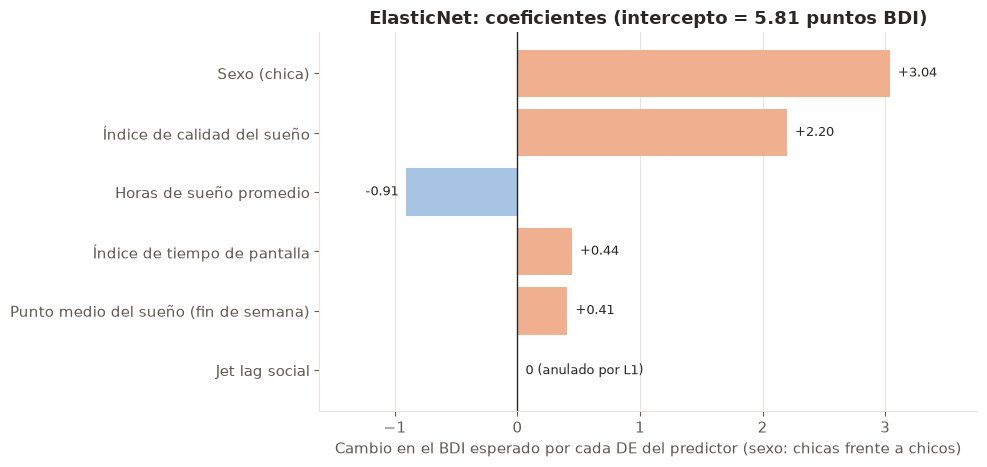

In [6]:
fig = graficar_coeficientes(coeficientes, elasticnet.intercept_)
plt.show()

El intercepto de 5.81 puntos corresponde al BDI esperado de un chico con todas las variables numéricas en su media. Como el modelo está regularizado, sus coeficientes están ligeramente encogidos hacia 0 y no tienen p-valores asociados. La penalización elegida es pequeña, por lo que su efecto más visible es la eliminación del jet lag social, cuya información ya está contenida en el punto medio del sueño del fin de semana.

## 2. Importancia Nativa (CatBoost)

CatBoost calcula dos importancias propias:

- **`PredictionValuesChange`:** cuánto cambia, en promedio, la predicción cuando cambia el valor de la variable (normalizada para que sume 100). Se calcula con la estructura de los árboles, sin datos.
- **`LossFunctionChange`:** cuánto empeora la pérdida (Logloss) al quitar la variable del modelo. Se calcula con un `Pool` del test ya preprocesado, así que mide la contribución de cada variable al desempeño en datos no vistos.

In [7]:
importancia_nativa = importancia_catboost(catboost, X_test_clf, y_dep_test, nombres)
importancia_nativa.round(3)

,PredictionValuesChange,LossFunctionChange
Variable,,
Índice de calidad del sueño,30.606,0.039
Sexo (chica),26.968,0.015
Horas de sueño promedio,14.257,0.004
Punto medio del sueño (fin de semana),10.838,0.002
Jet lag social,9.573,0.002
Índice de tiempo de pantalla,7.758,0.001


Las dos importancias nativas ordenan las variables de la misma forma. Según `PredictionValuesChange`, la calidad del sueño (30.606) y el sexo (26.968) concentran más de la mitad del cambio de las predicciones, seguidos de la duración del sueño (14.257), el punto medio del sueño (10.838), el jet lag social (9.573) y el tiempo de pantalla (7.758). `LossFunctionChange` acentúa la ventaja de la calidad del sueño: quitarla aumenta la pérdida en 0.039, más del doble que el sexo (0.015) y casi diez veces más que la duración del sueño (0.004), mientras que las tres variables restantes apenas aportan al desempeño en test (0.001 a 0.002).

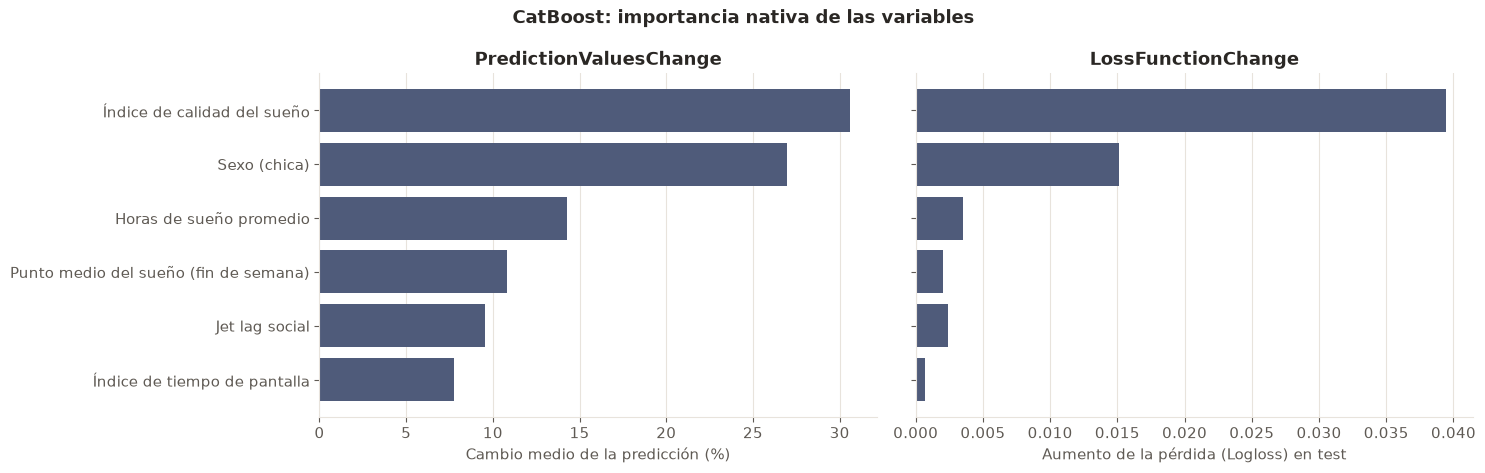

In [8]:
fig = graficar_importancia_catboost(importancia_nativa)
plt.show()

La gráfica evidencia que `PredictionValuesChange` distribuye la importancia de forma más uniforme que `LossFunctionChange`. El modelo emplea todas las variables para construir sus predicciones, pero la mejora del desempeño en datos nuevos proviene casi por completo de la calidad del sueño y del sexo. Que el sexo ocupe el segundo lugar en ambas medidas, pese a ser binario, indica que su efecto es lo bastante grande para compensar la desventaja de este tipo de variables en la importancia nativa.

**Limitaciones de la importancia nativa:**

- **No indica la dirección del efecto:** dice cuánto pesa una variable, pero no si aumenta o reduce el riesgo.
- **Favorece a las variables continuas con muchos valores distintos**, porque ofrecen más puntos de corte a los árboles. Puede subestimar a `sex`, que es binaria y solo admite una división.
- **Reparte la importancia entre variables correlacionadas.** `midsleep_weekend_hours` y `social_jetlag_hours` (r = 0.84) contienen información parecida, y el modelo puede usar una u otra de forma intercambiable, así que la importancia de cada una por separado subestima la del dominio que comparten.

## 3. SHAP

Los valores SHAP reparten la predicción de cada adolescente entre las variables: para cada observación, **la base (la predicción media) más la suma de sus valores SHAP es igual a la predicción del modelo**. Un valor positivo indica que esa variable empuja la predicción hacia arriba en ese adolescente, y uno negativo, hacia abajo. A diferencia de la importancia nativa, SHAP da la dirección del efecto y explica cada predicción individual.

Los `shap.Explanation` se construyen con los valores originales de las variables (sin estandarizar) y nombres legibles, así que los ejes y los colores se leen en las unidades de cada variable.

### CatBoost

`shap.TreeExplainer` calcula los valores SHAP exactos del ensamble sobre el test preprocesado. Están en **escala log-odds**: la base es el log-odds medio de depresión, y la suma de los SHAP de un adolescente da su log-odds, que se convierte en probabilidad con la función logística. Un SHAP de +0.5 multiplica las odds por e^0.5 ≈ 1.65. La comprobación de aditividad confirma que la base más la suma de los SHAP reproduce la salida del modelo.

In [9]:
shap_clf = shap_catboost(catboost, X_test_clf, originales_test)

print(f"Base (log-odds medio): {shap_clf.base_values[0]:.3f}")
print(f"Aditividad, máxima diferencia con la salida del modelo: {verificar_aditividad(shap_clf, salida_logodds_catboost(catboost, X_test_clf)):.2e}")
importancia_shap(shap_clf).round(4).to_frame()

Base (log-odds medio): -1.925
Aditividad, máxima diferencia con la salida del modelo: 4.88e-15


,Media de |SHAP|
Sexo (chica),0.5446
Índice de calidad del sueño,0.4104
Horas de sueño promedio,0.1915
Punto medio del sueño (fin de semana),0.1049
Índice de tiempo de pantalla,0.0881
Jet lag social,0.0525


Según la media de |SHAP|, el sexo es la variable con mayor contribución promedio (0.5446 log-odds), seguida de la calidad del sueño (0.4104), la duración del sueño (0.1915), el punto medio del sueño (0.1049), el tiempo de pantalla (0.0881) y el jet lag social (0.0525). La base del modelo es de −1.925 log-odds y la comprobación de aditividad arroja una diferencia máxima de 4.88e-15 con la salida del modelo, por lo que la descomposición es exacta.

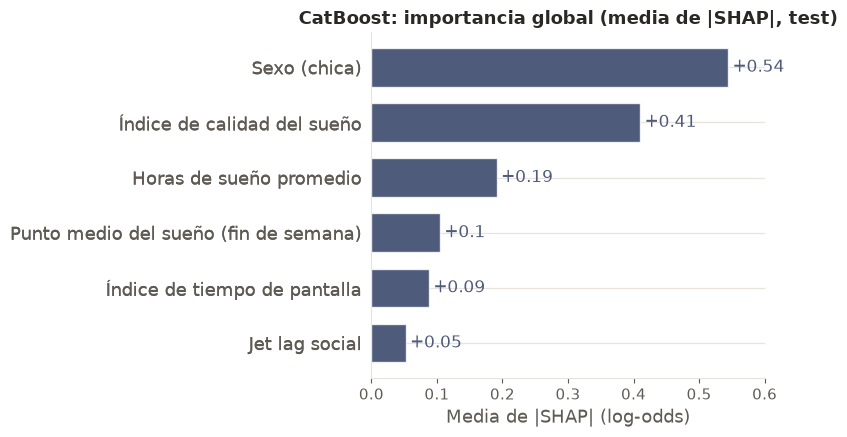

In [10]:
fig = graficar_shap_barras(shap_clf, "CatBoost: importancia global (media de |SHAP|, test)", "log-odds")
plt.show()

Este orden difiere del de la importancia nativa, en la que la calidad del sueño ocupaba el primer lugar. El sexo desplaza a todos los adolescentes en una magnitud similar, lo que eleva su |SHAP| medio, mientras que el efecto de la calidad del sueño es pequeño para la mayoría y muy grande para unos pocos, con valores de hasta cerca de +1.9 log-odds. La media de |SHAP| refleja, por tanto, el efecto típico de cada variable, y `LossFunctionChange`, la información que mejora la clasificación, criterio en el que predomina la calidad del sueño.

En el beeswarm, cada punto es un adolescente del test. La posición horizontal es su valor SHAP y el color, el valor original de la variable (rojo = alto, azul = bajo). Si los puntos rojos quedan a la derecha, valores altos de la variable aumentan el riesgo.

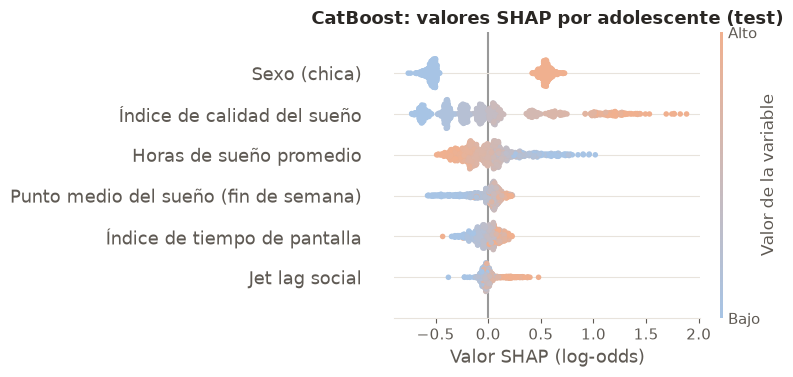

In [11]:
fig = graficar_shap_beeswarm(shap_clf, "CatBoost: valores SHAP por adolescente (test)", "log-odds")
plt.show()

El beeswarm muestra la dirección de cada efecto. Las chicas suman alrededor de +0.55 log-odds y los chicos restan una cantidad similar. Los valores altos del índice de calidad del sueño aumentan el riesgo, con una cola que llega a cerca de +1.9 log-odds, mientras que los valores bajos lo reducen hasta aproximadamente −0.7. Dormir pocas horas incrementa el riesgo hasta cerca de +1.0 log-odds, y dormir muchas lo disminuye. El punto medio del sueño, el tiempo de pantalla y el jet lag social aumentan levemente el riesgo en sus valores altos, con contribuciones inferiores a ±0.3 log-odds en la mayoría de los adolescentes, aunque el jet lag social presenta una pequeña cola positiva en sus valores más extremos.

**Dependence plots.** Para las 3 variables más importantes según SHAP, el valor original de la variable (eje x) frente a su valor SHAP (eje y), coloreados por sexo. Muestran la forma del efecto (lineal, con umbrales o saturación) y si difiere entre chicos y chicas, que es lo que un árbol puede capturar y un modelo lineal no.

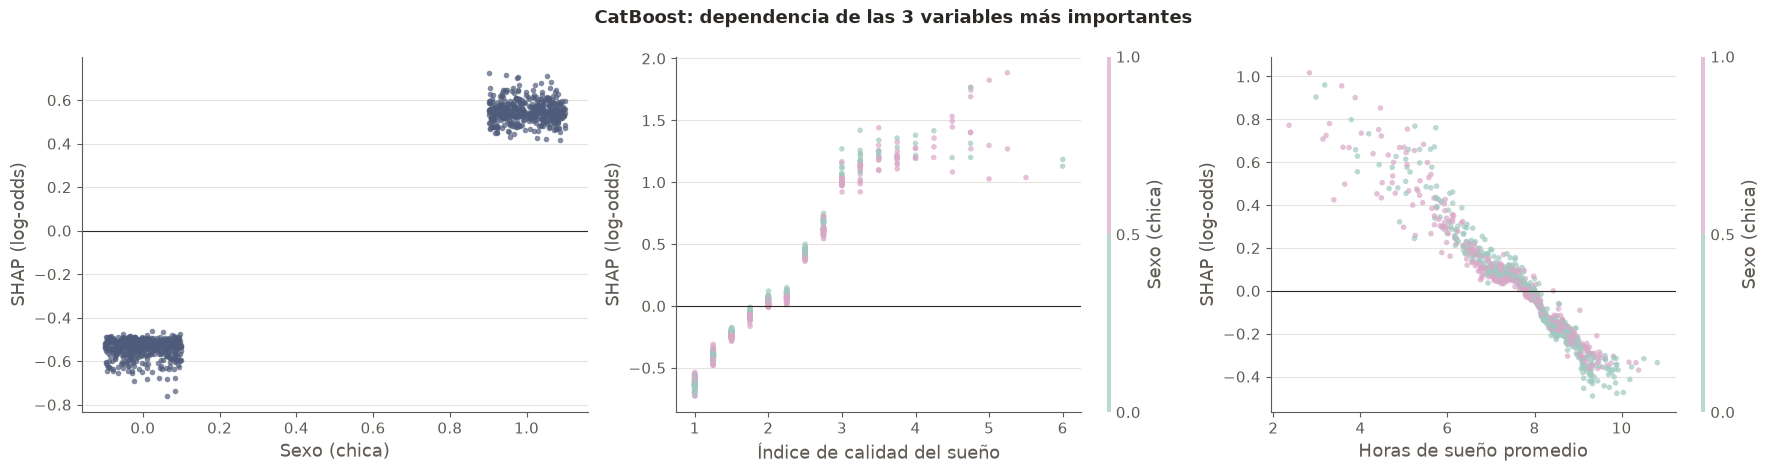

In [12]:
top_clf = list(importancia_shap(shap_clf).index[:3])
fig = graficar_dependencias(shap_clf, top_clf, "CatBoost: dependencia de las 3 variables más importantes", "log-odds")
plt.show()

Los dependence plots revelan formas que un modelo lineal no captura. El efecto de la calidad del sueño crece de forma casi lineal entre 1 y 3 puntos del índice, de aproximadamente −0.6 a +1.2 log-odds, y a partir de ese valor se satura, de modo que un empeoramiento adicional apenas incrementa el riesgo. El efecto de las horas de sueño es casi lineal y decreciente, desde cerca de +1.0 log-odds con 3 horas hasta −0.4 con 10 horas. En ninguna de las variables numéricas se separan los puntos de chicos y chicas, lo que indica que el modelo no encontró interacciones relevantes con el sexo y que su efecto es aditivo.

**Explicaciones individuales.** Se eligen 3 adolescentes del test de forma reproducible (`SEED` = 42), según la clasificación con el umbral de tamizaje del modelo final: un verdadero positivo, un falso negativo y un falso positivo. El waterfall muestra cómo cada variable lleva el log-odds desde la base hasta el valor de ese adolescente.

In [13]:
proba_test = clasificador.predict_proba(X_test)[:, 1]
casos_clf = elegir_casos_clasificacion(y_dep_test, proba_test, UMBRAL, subject_id_test, seed=SEED)
casos_clf

,posicion,subject_id,Real,Predicción,Motivo
Caso,,,,,
Verdadero positivo,104,544,1,0.613,verdadero positivo: deprimido y probabilidad ≥ 0.153 (elegido al azar con SEED = 42)
Falso negativo,807,4139,1,0.137,falso negativo: deprimido pero probabilidad < 0.153 (elegido al azar con SEED = 42)
Falso positivo,613,3169,0,0.222,falso positivo: no deprimido pero probabilidad ≥ 0.153 (elegido al azar con SEED = 42)


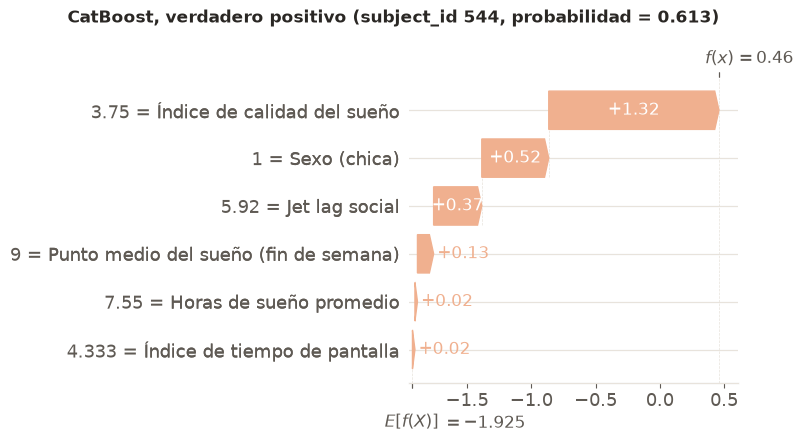

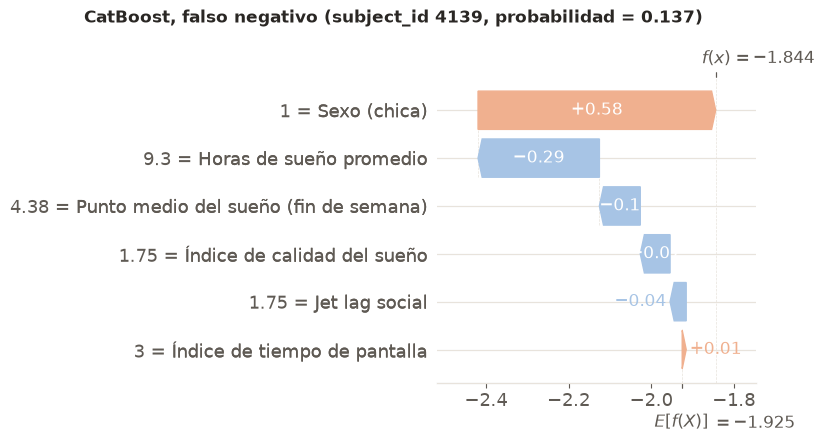

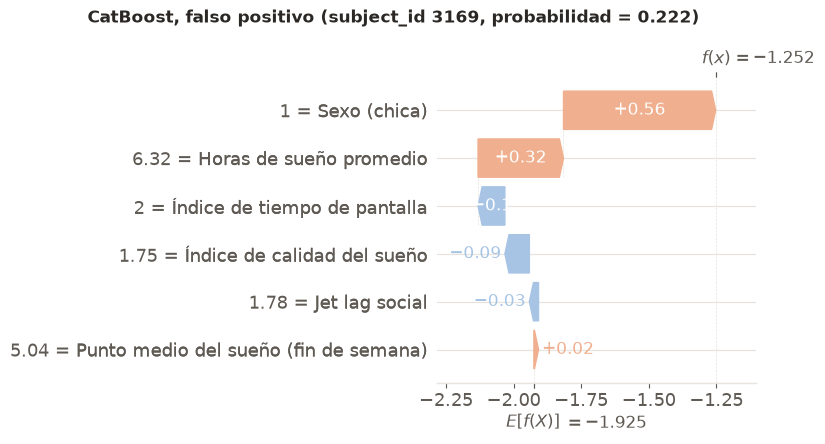

In [14]:
for caso, fila in casos_clf.iterrows():
    fig = graficar_waterfall(shap_clf, fila["posicion"], f"CatBoost, {caso.lower()} (subject_id {fila['subject_id']}, probabilidad = {fila['Predicción']:.3f})")
    plt.show()

El verdadero positivo (subject_id 544, probabilidad de 0.613) es una chica con un índice de calidad del sueño de 3.75, que por sí solo aporta +1.32 log-odds; el sexo (+0.52) y un jet lag social de 5.92 horas (+0.37) completan su riesgo. El falso negativo (subject_id 4139, probabilidad de 0.137, inferior al umbral de 0.153) es una chica deprimida con buenos hábitos de sueño, con 9.3 horas de sueño (−0.29) y un índice de calidad del sueño de 1.75 de efecto casi nulo, de manera que la contribución del sexo (+0.58) no alcanza para superar el umbral. Este caso ilustra que el modelo no puede detectar una depresión que no se refleja en el sueño ni en el tiempo de pantalla. El falso positivo (subject_id 3169, probabilidad de 0.222) es una chica no deprimida que duerme 6.32 horas (+0.32); la combinación del sexo (+0.56) y la escasa duración del sueño basta para superar el umbral de tamizaje.

### ElasticNet

`shap.LinearExplainer` usa el train preprocesado como datos de fondo, así que la base es la predicción media del train y los valores SHAP están en **puntos BDI**. En un modelo lineal, el SHAP de una variable es simplemente el coeficiente por la desviación del valor respecto a su media: $\phi_j = \beta_j (x_j - \bar x_j)$. Por eso su ranking global es casi el mismo que el de los coeficientes de la sección 1 (multiplicados por la dispersión de cada variable) y el beeswarm muestra, para cada variable, una recta. SHAP explica la salida lineal del ElasticNet, antes del recorte de las predicciones a [0, 63].

In [15]:
shap_reg = shap_lineal(elasticnet, X_train_reg, X_test_reg, originales_test)

print(f"Base (BDI medio predicho en el train): {shap_reg.base_values[0]:.3f}")
print(f"Aditividad, máxima diferencia con la salida del ElasticNet: {verificar_aditividad(shap_reg, elasticnet.predict(X_test_reg)):.2e}")
importancia_shap(shap_reg).round(4).to_frame()

Base (BDI medio predicho en el train): 7.496
Aditividad, máxima diferencia con la salida del ElasticNet: 3.55e-15


,Media de |SHAP|
Índice de calidad del sueño,1.6754
Sexo (chica),1.5226
Horas de sueño promedio,0.7083
Índice de tiempo de pantalla,0.3737
Punto medio del sueño (fin de semana),0.3451
Jet lag social,0.0000


La base del ElasticNet es de 7.496 puntos BDI, la predicción media del train, y la diferencia máxima de aditividad es de 3.55e-15. La calidad del sueño presenta la mayor contribución media (1.6754 puntos BDI), seguida de cerca por el sexo (1.5226), la duración del sueño (0.7083), el tiempo de pantalla (0.3737) y el punto medio del sueño (0.3451). La contribución del jet lag social es exactamente 0, en coherencia con su coeficiente nulo.

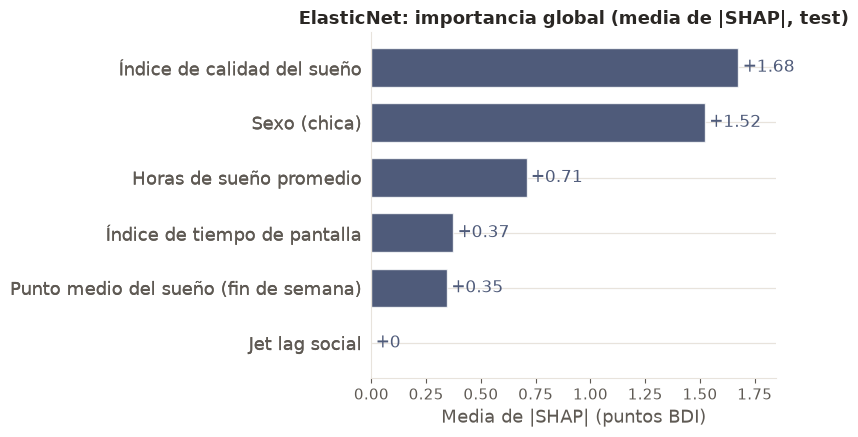

In [16]:
fig = graficar_shap_barras(shap_reg, "ElasticNet: importancia global (media de |SHAP|, test)", "puntos BDI")
plt.show()

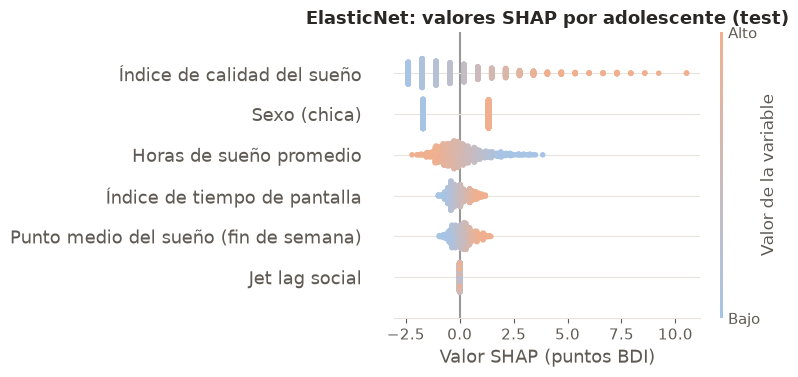

In [17]:
fig = graficar_shap_beeswarm(shap_reg, "ElasticNet: valores SHAP por adolescente (test)", "puntos BDI")
plt.show()

Al tratarse de un modelo lineal, cada variable forma una banda ordenada por color, ya que el valor SHAP es proporcional a la distancia entre el valor de la variable y su media. El sexo divide a los adolescentes en dos grupos, con contribuciones de −1.70 puntos en los chicos y de +1.34 en las chicas. La calidad del sueño presenta la cola más extensa, con contribuciones de hasta cerca de +10 puntos BDI en los adolescentes con peor sueño, mientras que la duración del sueño, el tiempo de pantalla y el punto medio del sueño se mueven en rangos considerablemente más estrechos.

**Explicaciones individuales.** Se eligen 3 adolescentes del test de forma reproducible (`SEED` = 42) según su BDI real: uno bajo (≤ 2), uno cercano al corte clínico (13 a 15) y uno alto (≥ percentil 95 del test).

In [18]:
bdi_predicho = regresor.predict(X_test)
casos_reg = elegir_casos_regresion(y_bdi_test, bdi_predicho, subject_id_test, seed=SEED)
casos_reg

,posicion,subject_id,Real,Predicción,Motivo
Caso,,,,,
BDI bajo,92,473,2,11.73,BDI real ≤ 2 (elegido al azar con SEED = 42)
BDI cercano a 14,797,4092,13,3.32,BDI real entre 13 y 15 (cerca del corte clínico) (elegido al azar con SEED = 42)
BDI alto,661,3403,22,16.09,BDI real ≥ 22 (percentil 95 del test) (elegido al azar con SEED = 42)


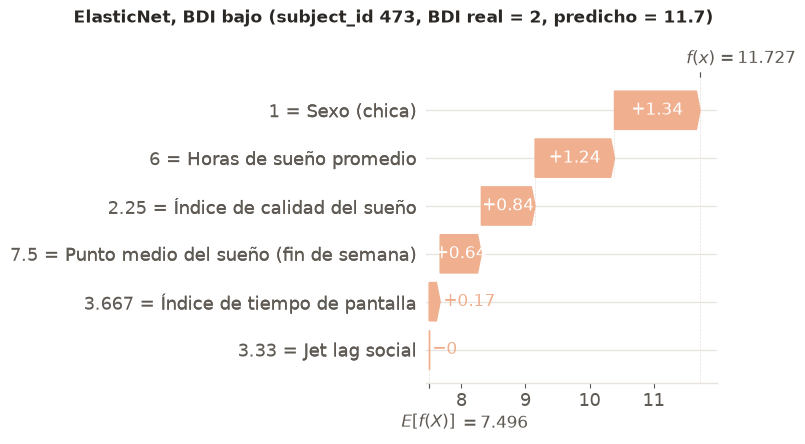

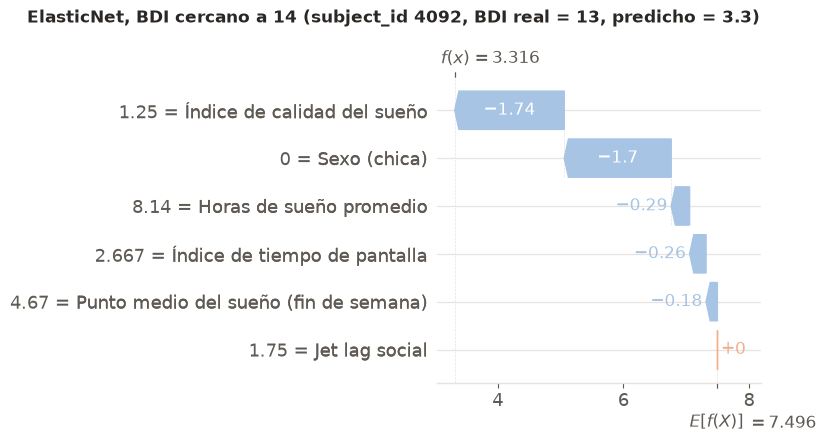

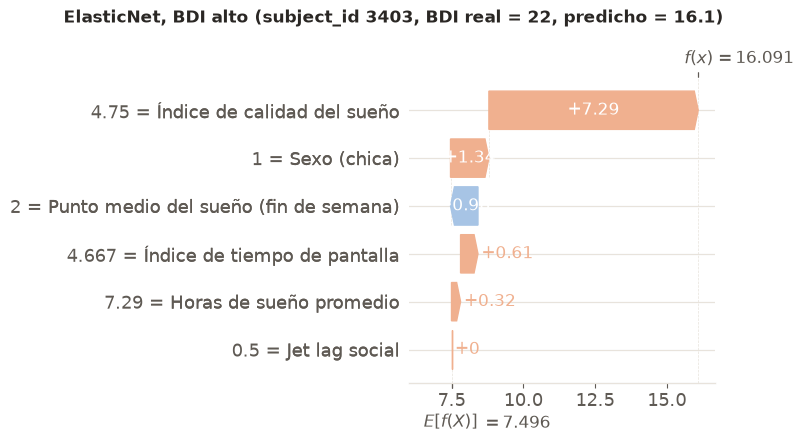

In [19]:
for caso, fila in casos_reg.iterrows():
    fig = graficar_waterfall(shap_reg, fila["posicion"], f"ElasticNet, {caso} (subject_id {fila['subject_id']}, BDI real = {fila['Real']}, predicho = {fila['Predicción']:.1f})")
    plt.show()

En el caso de BDI bajo (subject_id 473, BDI real de 2 y predicho de 11.7), el modelo sobreestima el puntaje en casi 10 puntos. Se trata de una chica (+1.34) que duerme 6 horas (+1.24), con un índice de calidad del sueño de 2.25 (+0.84) y un punto medio del sueño de 7.5 horas (+0.64): un perfil de riesgo con un BDI real casi nulo. El caso cercano al corte clínico (subject_id 4092, BDI real de 13 y predicho de 3.3) muestra el error opuesto, el de un chico (−1.70) con un índice de calidad del sueño de 1.25 (−1.74) y 8.14 horas de sueño (−0.29), cuyo perfil apunta a un BDI bajo. El caso de BDI alto (subject_id 3403, BDI real de 22 y predicho de 16.1) es el mejor explicado, pues su índice de calidad del sueño de 4.75 aporta +7.29 puntos, aunque el modelo aún lo subestima en 6 puntos. En conjunto, los tres casos muestran que los predictores capturan el riesgo promedio asociado a un perfil, pero no la variabilidad individual del BDI.

## 4. LIME

LIME explica una predicción individual ajustando un **modelo lineal simple alrededor de ese adolescente**: genera muchas observaciones perturbadas cerca de él, obtiene la predicción del modelo para cada una y ajusta una regresión ponderada por cercanía. Los pesos de esa regresión son la explicación local.

- Trabaja sobre las **variables originales**, con el train sin preprocesar como referencia. Las numéricas se discretizan en cuartiles, por eso cada barra es una regla (por ejemplo, "Índice de calidad del sueño > 2.75"), y `sex` se trata como categórica.
- La función de predicción convierte el array de LIME en un DataFrame con las columnas y tipos originales (`sex` de vuelta a "Boy"/"Girl") y llama al **pipeline completo guardado**, con el mismo preprocesamiento que en el modelado.
- Se explican los **mismos 3 adolescentes** de la sección 3, con `num_samples=5000` y `random_state=42`. En CatBoost se explica la probabilidad de la clase "Deprimido" (`predict_proba`) y en ElasticNet, el BDI predicho (`predict`).

### CatBoost

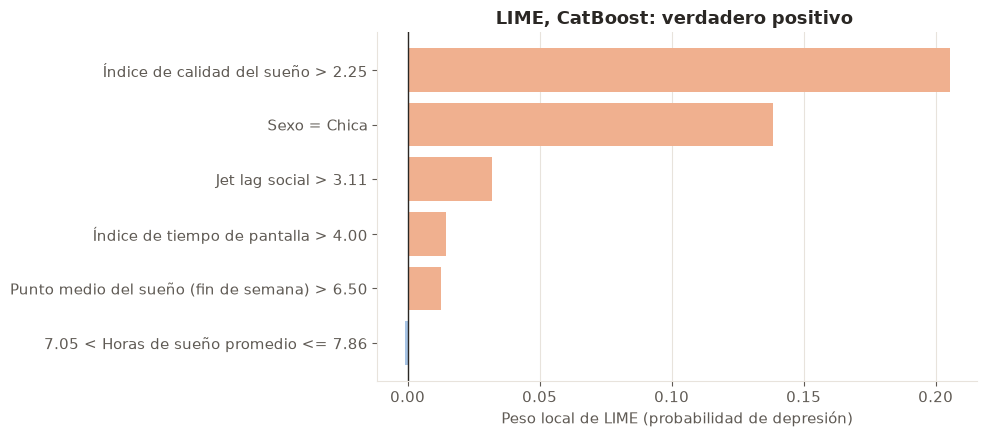

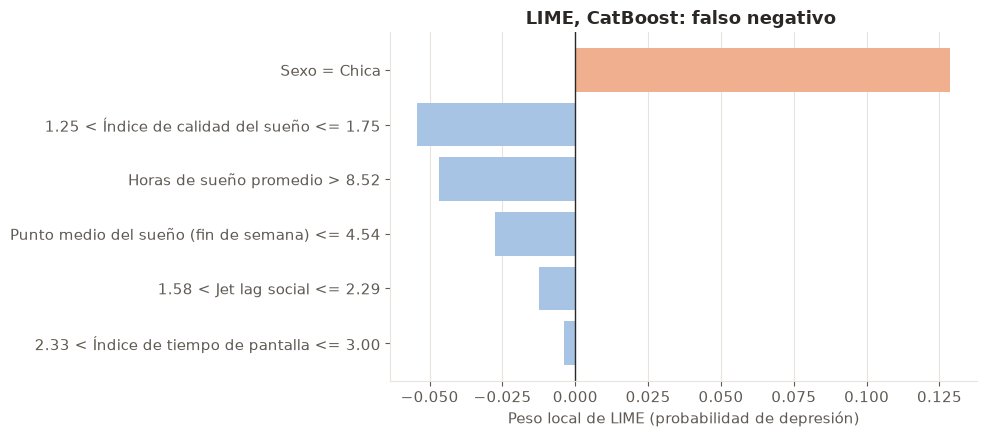

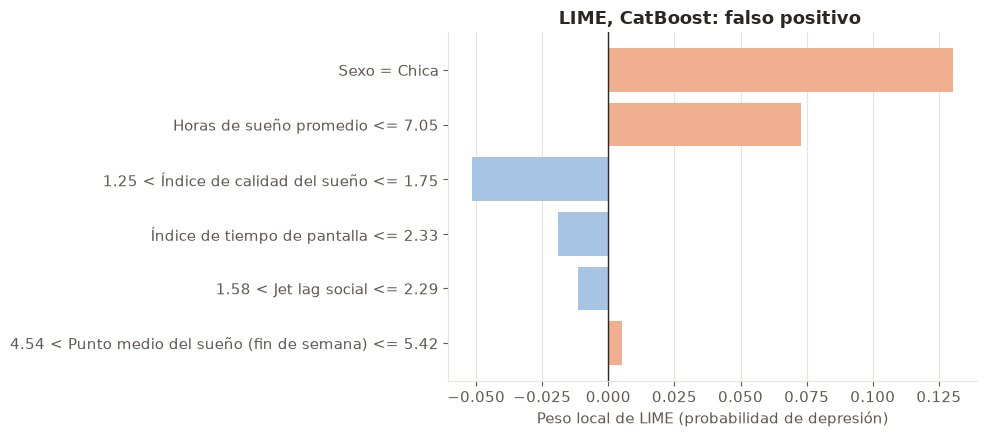

In [20]:
explicador_clf = crear_explicador_lime(X_train, "classification", seed=SEED)
lime_clf = explicar_lime(explicador_clf, clasificador, "classification", X_test, casos_clf, num_samples=5000)

for caso, explicacion in lime_clf.items():
    fig = graficar_lime(explicacion, f"LIME, CatBoost: {caso.lower()} ", "probabilidad de depresión")
    plt.show()

### ElasticNet

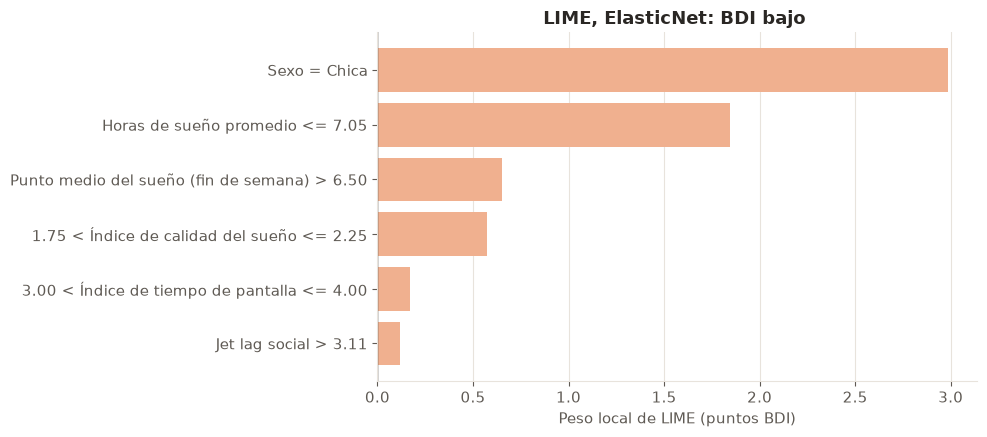

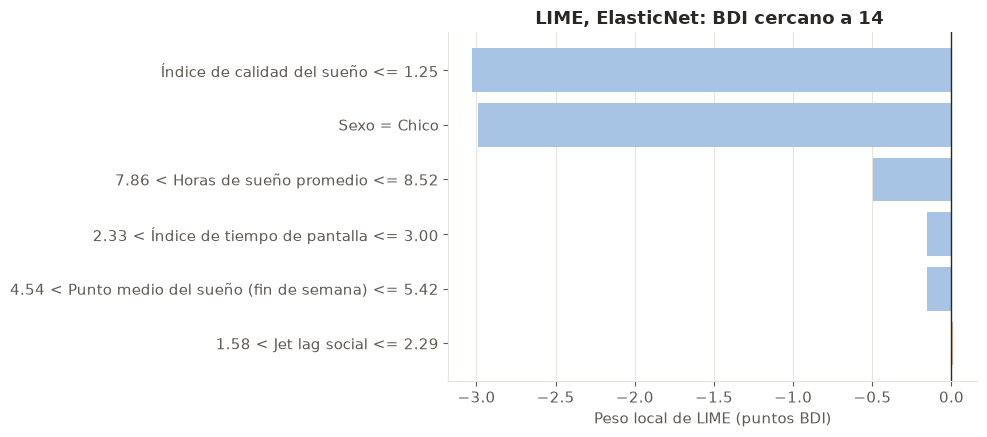

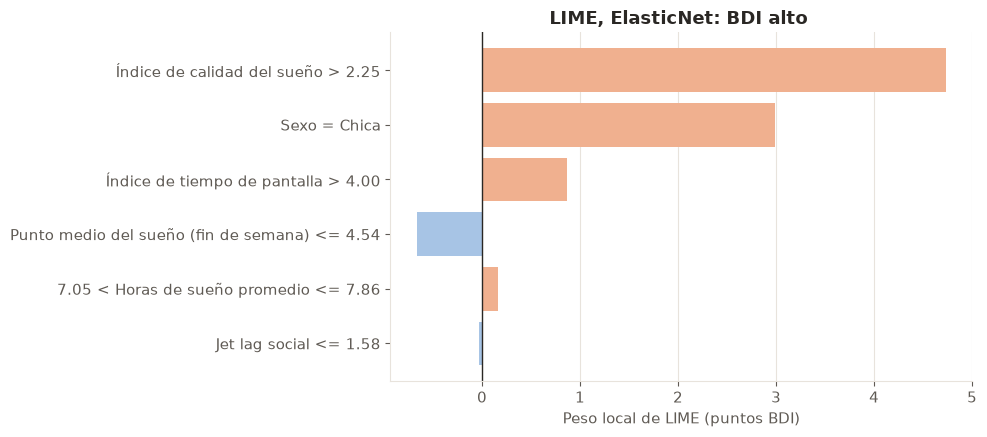

In [21]:
explicador_reg = crear_explicador_lime(X_train, "regression", seed=SEED)
lime_reg = explicar_lime(explicador_reg, regresor, "regression", X_test, casos_reg, num_samples=5000)

for caso, explicacion in lime_reg.items():
    fig = graficar_lime(explicacion, f"LIME, ElasticNet: {caso} ", "puntos BDI")
    plt.show()

### LIME frente a SHAP

Para cada adolescente, las 3 variables con mayor peso en valor absoluto según LIME y según SHAP. Las escalas no son comparables: en CatBoost, LIME está en probabilidad y SHAP en log-odds; en ElasticNet, ambos están en puntos BDI, pero LIME mide el efecto de una regla (por ejemplo, estar en el cuartil superior) y SHAP, el de la desviación respecto a la media. Lo que se compara es el **orden** y el **signo**.

In [22]:
comparar_lime_shap(casos_clf, lime_clf, shap_clf, top=3).round(4)

LIME: variable  LIME: peso  \
Caso               Puesto                                            
Verdadero positivo 1       Índice de calidad del sueño      0.2053   
                   2                      Sexo (chica)      0.1383   
                   3                    Jet lag social      0.0320   
Falso negativo     1                      Sexo (chica)      0.1287   
                   2       Índice de calidad del sueño     -0.0543   
                   3           Horas de sueño promedio     -0.0466   
Falso positivo     1                      Sexo (chica)      0.1303   
                   2           Horas de sueño promedio      0.0728   
                   3       Índice de calidad del sueño     -0.0513   

                                                  SHAP: variable  SHAP: valor  \
Caso               Puesto                                                       
Verdadero positivo 1                 Índice de calidad del sueño       1.3242   
                   2                                Sexo (chica)       0.5211   
                   3                              Jet lag social       0.3747   
Falso negativo     1                                Sexo (chica)       0.5755   
                   2                     Horas de sueño promedio      -0.2939   
                   3       Punto medio del sueño (fin de semana)      -0.0990   
Falso positivo     1                                Sexo (chica)       0.5630   
                   2                     Horas de sueño promedio       0.3161   
                   3                Índice de tiempo de pantalla      -0.0993   

                           Misma variable  
Caso               Puesto                  
Verdadero positivo 1                 True  
                   2                 True  
                   3                 True  
Falso negativo     1                 True  
                   2                False  
                   3                False  
Falso positivo     1                 True  
                   2                 True  
                   3                False

En CatBoost, LIME y SHAP coinciden en las tres variables principales del verdadero positivo (calidad del sueño, sexo y jet lag social) y en las dos primeras del falso positivo (sexo y horas de sueño). En el falso negativo solo coinciden en la primera, el sexo, y difieren en las siguientes, que reciben pesos pequeños en ambos métodos. Las discrepancias se concentran así en las variables de efecto reducido, donde la aproximación lineal local de LIME y el reparto exacto de SHAP no tienen por qué producir el mismo orden.

In [23]:
comparar_lime_shap(casos_reg, lime_reg, shap_reg, top=3).round(4)

LIME: variable  LIME: peso  \
Caso             Puesto                                                      
BDI bajo         1                                Sexo (chica)      2.9883   
                 2                     Horas de sueño promedio      1.8440   
                 3       Punto medio del sueño (fin de semana)      0.6505   
BDI cercano a 14 1                 Índice de calidad del sueño     -3.0252   
                 2                                Sexo (chica)     -2.9885   
                 3                     Horas de sueño promedio     -0.4954   
BDI alto         1                 Índice de calidad del sueño      4.7327   
                 2                                Sexo (chica)      2.9906   
                 3                Índice de tiempo de pantalla      0.8677   

                                                SHAP: variable  SHAP: valor  \
Caso             Puesto                                                       
BDI bajo         1                                Sexo (chica)       1.3372   
                 2                     Horas de sueño promedio       1.2401   
                 3                 Índice de calidad del sueño       0.8390   
BDI cercano a 14 1                 Índice de calidad del sueño      -1.7425   
                 2                                Sexo (chica)      -1.7019   
                 3                     Horas de sueño promedio      -0.2929   
BDI alto         1                 Índice de calidad del sueño       7.2927   
                 2                                Sexo (chica)       1.3372   
                 3       Punto medio del sueño (fin de semana)      -0.9566   

                         Misma variable  
Caso             Puesto                  
BDI bajo         1                 True  
                 2                 True  
                 3                False  
BDI cercano a 14 1                 True  
                 2                 True  
                 3                 True  
BDI alto         1                 True  
                 2                 True  
                 3                False

En el ElasticNet la concordancia es mayor: las dos primeras variables coinciden en los tres casos y, en el caso cercano al corte clínico, coinciden las tres. Las diferencias se limitan a la tercera posición y a la magnitud de los pesos. LIME asigna al sexo cerca de 2.99 puntos, que corresponden a la diferencia entre chicas y chicos, mientras que SHAP le asigna 1.3372 o −1.7019 porque compara con el adolescente medio. Del mismo modo, en el caso de BDI alto LIME atribuye a la calidad del sueño 4.7327 puntos y SHAP 7.2927, ya que LIME mide el efecto de superar un umbral del cuartil superior y SHAP, el de la distancia exacta a la media.

**Coincidencias y diferencias.** Los dos métodos parten de ideas distintas. SHAP reparte la predicción de forma exacta entre las variables respecto a una referencia, la predicción media. LIME aproxima el modelo con una recta solo en el entorno del adolescente, usando reglas discretizadas. Cuando el modelo es casi lineal en ese entorno, como el ElasticNet, ambos tienden a coincidir en las variables principales y en su signo. En CatBoost pueden diferir más, porque el modelo tiene umbrales e interacciones y LIME los resume en una aproximación lineal local.

**Variabilidad.** LIME se basa en un muestreo aleatorio de observaciones perturbadas, así que sus pesos pueden cambiar entre ejecuciones (aquí se fijan con `random_state=42` y 5000 muestras) y con el número de muestras o la discretización elegida. SHAP, en cambio, es determinista para estos dos modelos.

## 5. Permutation Importance (ElasticNet)

La permutation importance mide **cuánto empeora el modelo al romper la relación de cada variable con el target**: se desordenan los valores de una variable en el test (30 repeticiones) y se mide cuánto aumenta el RMSE. Se calcula con el pipeline completo guardado (`scoring="neg_root_mean_squared_error"`, `n_repeats=30`, `random_state=42`) y es **agnóstica al modelo**: solo necesita sus predicciones. A diferencia de los coeficientes y de SHAP, que describen cómo usa el modelo cada variable, mide cuánto depende de ella su **desempeño** en datos no vistos.

In [24]:
permutacion = importancia_permutacion(regresor, X_test, y_bdi_test, n_repeats=30, seed=SEED)
permutacion.round(4)

,Aumento del RMSE (media),DE
Variable,,
Índice de calidad del sueño,0.7435,0.0869
Sexo (chica),0.3761,0.0574
Horas de sueño promedio,0.0911,0.0270
Índice de tiempo de pantalla,0.0381,0.0137
Punto medio del sueño (fin de semana),0.0200,0.0135
Jet lag social,0.0000,0.0000


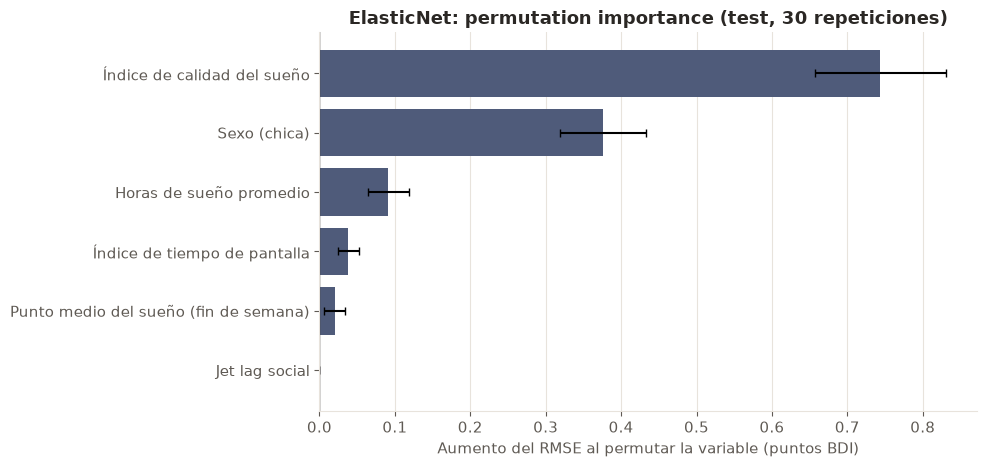

In [25]:
fig = graficar_permutacion(permutacion, "ElasticNet: permutation importance (test, 30 repeticiones)")
plt.show()

La calidad del sueño es, con diferencia, la variable de la que más depende el ElasticNet: su permutación aumenta el RMSE en 0.7435 ± 0.0869 puntos BDI. Le siguen el sexo (0.3761 ± 0.0574) y, a gran distancia, la duración del sueño (0.0911 ± 0.0270), el tiempo de pantalla (0.0381 ± 0.0137) y el punto medio del sueño del fin de semana (0.0200 ± 0.0135), mientras que la permutación del jet lag social no altera el RMSE (0.0000 ± 0.0000) porque su coeficiente es nulo.

El orden coincide exactamente con el de la media de |SHAP| y, entre las variables numéricas, con el de los coeficientes por desviación estándar. La única diferencia es el sexo, cuyo coeficiente (3.039) es el mayor pero corresponde a pasar de chico a chica; en SHAP y en la permutation importance, que consideran cuántos adolescentes hay en cada grupo, ocupa el segundo lugar. La permutation importance, además, amplifica las distancias entre variables: la calidad del sueño pesa el doble que el sexo (0.7435 frente a 0.3761), mientras que en SHAP sus contribuciones son cercanas (1.6754 frente a 1.5226).

### Guardado

Se guardan en `data/processed/modelado/interpretabilidad/`:

- `importancias.csv`, en formato largo: modelo, método (`coeficiente`, `prediction_values_change`, `loss_function_change`, `shap_global` o `permutacion`), variable, valor y desviación (solo en la permutation importance).
- `casos_explicados.csv`: el `subject_id` de cada adolescente explicado y por qué se eligió.

In [26]:
importancias = tabla_importancias([
    ("elasticnet", "coeficiente", coeficientes["Coeficiente (por DE)"], None),
    ("catboost", "prediction_values_change", importancia_nativa["PredictionValuesChange"], None),
    ("catboost", "loss_function_change", importancia_nativa["LossFunctionChange"], None),
    ("catboost", "shap_global", importancia_shap(shap_clf), None),
    ("elasticnet", "shap_global", importancia_shap(shap_reg), None),
    ("elasticnet", "permutacion", permutacion["Aumento del RMSE (media)"], permutacion["DE"]),
])
guardar_resultados(importancias, {"catboost": casos_clf, "elasticnet": casos_reg})
importancias.pivot_table(index="variable", columns=["modelo", "metodo"], values="valor").round(3)

✓ Guardado en /workspace/data/processed/modelado/interpretabilidad: importancias.csv y casos_explicados.csv


modelo                                            catboost  \
metodo                                loss_function_change   
variable                                                     
Horas de sueño promedio                              0.004   
Jet lag social                                       0.002   
Punto medio del sueño (fin de semana)                0.002   
Sexo (chica)                                         0.015   
Índice de calidad del sueño                          0.039   
Índice de tiempo de pantalla                         0.001   

modelo                                                                      \
metodo                                prediction_values_change shap_global   
variable                                                                     
Horas de sueño promedio                                 14.257       0.191   
Jet lag social                                           9.573       0.052   
Punto medio del sueño (fin de semana)                   10.838       0.105   
Sexo (chica)                                            26.968       0.545   
Índice de calidad del sueño                             30.606       0.410   
Índice de tiempo de pantalla                             7.758       0.088   

modelo                                 elasticnet                          
metodo                                coeficiente permutacion shap_global  
variable                                                                   
Horas de sueño promedio                    -0.905       0.091       0.708  
Jet lag social                              0.000       0.000       0.000  
Punto medio del sueño (fin de semana)       0.408       0.020       0.345  
Sexo (chica)                                3.039       0.376       1.523  
Índice de calidad del sueño                 2.199       0.743       1.675  
Índice de tiempo de pantalla                0.444       0.038       0.374

## 6. Conclusiones

La calidad del sueño es el predictor que más información aporta en ambos modelos. En el ElasticNet ocupa el primer lugar en la media de |SHAP| (1.6754 puntos BDI) y en la permutation importance (0.7435 ± 0.0869 puntos de RMSE), y presenta el mayor coeficiente entre las variables numéricas (2.199 por desviación estándar). En CatBoost encabeza las dos importancias nativas y, en `LossFunctionChange`, aporta más del doble que el sexo (0.039 frente a 0.015); solo en la media de |SHAP| queda en segundo lugar, detrás del sexo (0.4104 frente a 0.5446), porque su efecto es pequeño para la mayoría y muy grande para quienes duermen peor. En este modelo, además, su efecto se satura por encima de 3 puntos del índice.

El tiempo de pantalla ocupa un lugar secundario frente a los dominios del sueño. Es la última variable en las importancias nativas de CatBoost y la quinta en su media de |SHAP| (0.0881 log-odds), y la cuarta en el ElasticNet (0.3737 puntos BDI en SHAP y 0.0381 ± 0.0137 en la permutation importance). Su efecto tiene el signo esperado, con 0.434 puntos BDI por cada punto del índice, pero es mucho menor que el de la calidad y la duración del sueño.

El sexo es, junto con la calidad del sueño, el factor principal en ambos modelos: las chicas suman 3.039 puntos BDI en el ElasticNet y alrededor de +0.55 log-odds en CatBoost, con un efecto aditivo que no modifica la relación de las demás variables con el riesgo.

En lo esencial, CatBoost y ElasticNet coinciden en la jerarquía y en la dirección de los efectos. Ambos sitúan la calidad del sueño, el sexo y la duración del sueño como las tres variables principales, y coinciden en el signo de todos los efectos que comparten: una peor calidad del sueño, menos horas de sueño, ser chica, más tiempo de pantalla y un punto medio del sueño más tardío aumentan el riesgo. La principal diferencia es el jet lag social, que el ElasticNet anula y CatBoost emplea en sus valores altos, como en el verdadero positivo, donde aporta +0.37 log-odds; esto sugiere un efecto no lineal que el modelo lineal no recoge.